## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [28]:
# import pickle

# with open('data/all_tokens.pickle', 'rb') as file:
#     all_tokens = pickle.load(file)

# from collections import Counter
# token_count = Counter(all_tokens)
# token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Lani Le

**Date:** 10/18/26

In [29]:
# Your Phase 1 solution to the problem goes here.
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

---------------Question 1---------------


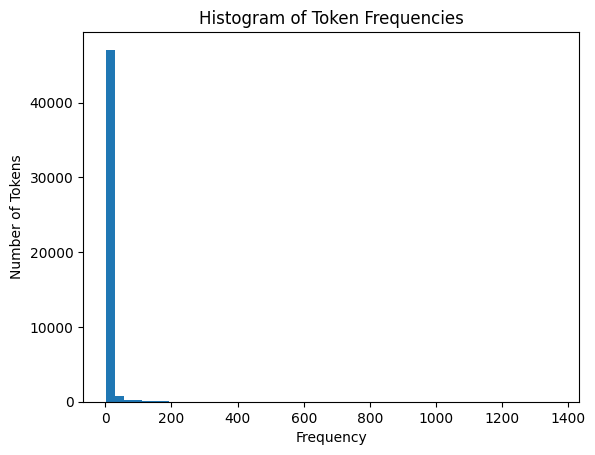


 I noticed that most of the tokens had low frequency, meaning they occurred very few times. However, there were a few tokens that did have a higher frequency. Overall, the distribution is extremely right skewed due to most tokens having low frequency.


In [30]:
print('---------------Question 1---------------')

# importing packages
import matplotlib.pyplot as plt

# plotting histogram
plt.hist(token_count.values(), bins=50)
plt.xlabel('Frequency')
plt.ylabel('Number of Tokens')
plt.title('Histogram of Token Frequencies')
plt.show()

print('\n I noticed that most of the tokens had low frequency, meaning they occurred very few times. However, there were a few tokens that did have a higher frequency. Overall, the distribution is extremely right skewed due to most tokens having low frequency.')

In [31]:
print('---------------Question 2---------------')

# importing packages
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# loading data set
df = pd.read_parquet('Phishing_clean.parquet')

# seperating features and target
X = df.drop(columns=['Email Type'])
y = df['Email Type']

# performing an 80/20 test train split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=65
)

# running a linear regression on training data
model = LinearRegression().fit(X_train, y_train)

# calculating r^2 values
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

# printing out r^2 values
print('R^2 of Training Set: ' + str(train_r2))
print('R^2 of Test Set: ' + str(test_r2))

---------------Question 2---------------
R^2 of Training Set: 0.7677733084118992
R^2 of Test Set: 0.6571173475409766


In [32]:
coefficients = pd.Series(model.coef_, index=X.columns)

top10_words = coefficients.abs().sort_values(ascending=False).head(10)

print('Top 10 Words with Largest Coefficients and Most Strongly Influence Predictions: ')
print(top10_words)

Top 10 Words with Largest Coefficients and Most Strongly Influence Predictions: 
aging                0.996514
helvetica,           0.892177
localized            0.787934
background-image:    0.780070
thermal              0.671019
12px;                0.629280
rcs                  0.553536
exercise!            0.542180
burning              0.515023
#000000;             0.502902
dtype: float64


---------------Question 3---------------


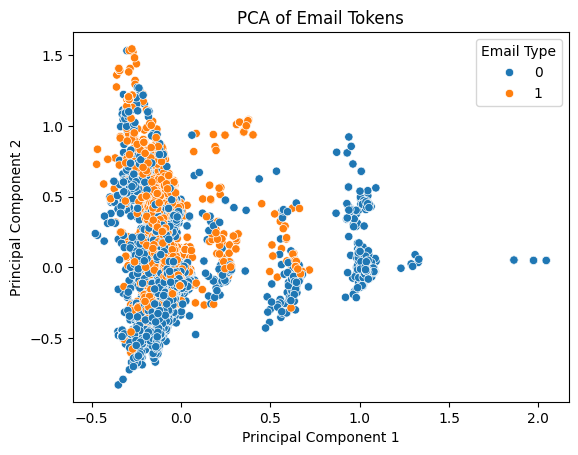

I noticed that on the left side of the graph, there is a lot of overlap between Email Type 0 and Email Type 1 (Scam Emails). On the right side of the graph, there is gradually less and less overlap and only values of Email Type 0 remain. Because there was overall a lot of overlap, it shows that plotting just the first two principal components is not enough to be able to clearly distinguish from scam emails and non-scam emails.


In [33]:
print('---------------Question 3---------------')

# importing packages
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# performing a PCA decomposition with two components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# creating a data frame for plotting
pca_df = pd.DataFrame(
    data=X_pca, columns=['Principal Component 1', 'Principal Component 2']
)
pca_df['Email Type'] = y.values

# plotting the components on a scatterplot
plt.figure()
sns.scatterplot(data=pca_df, x='Principal Component 1', y='Principal Component 2', hue='Email Type')
plt.title('PCA of Email Tokens')
plt.show()

print('I noticed that on the left side of the graph, there is a lot of overlap between Email Type 0 and Email Type 1 (Scam Emails). On the right side of the graph, there is gradually less and less overlap and only values of Email Type 0 remain. Because there was overall a lot of overlap, it shows that plotting just the first two principal components is not enough to be able to clearly distinguish from scam emails and non-scam emails.')

In [34]:
print('---------------Question 4---------------')
# performing a PCA decomposition with 2610 components
pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# running a linear regression on training data
pca_model = LinearRegression().fit(X_train_pca, y_train)

# calculating r^2 values
train_pca_r2 = pca_model.score(X_train_pca, y_train)
test_pca_r2 = pca_model.score(X_test_pca, y_test)

# printing out r^2 values
print('R^2 of Training Set: ' + str(train_pca_r2))
print('R^2 of Test Set: ' + str(test_pca_r2))

print('\n In comparison with the linear regression with 2 components, the new R^2 values were very similar, only varying about less than 0.01. This shows that the predicitve information stayed relatively the same in both models.')

---------------Question 4---------------
R^2 of Training Set: 0.7668967611277832
R^2 of Test Set: 0.6613559301353324

 In comparison with the linear regression with 2 components, the new R^2 values were very similar, only varying about less than 0.01. This shows that the predicitve information stayed relatively the same in both models.


In [35]:
print('---------------Question 5---------------')
print('The advantage is in using the principal component to run this high-dimensional regression rather than the original data is that it keeps the prediciative information while using fewer components, which we saw in the previous question. This ultimately makes the code more efficient, saving time, space, and memory.')

---------------Question 5---------------
The advantage is in using the principal component to run this high-dimensional regression rather than the original data is that it keeps the prediciative information while using fewer components, which we saw in the previous question. This ultimately makes the code more efficient, saving time, space, and memory.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]